# Week 15–16: Neural Networks from Scratch (NumPy) & Model Deployment Basics (Pickle/Joblib)

**Author:** [Dhanish Ladwani](https://github.com/dhanish0711/)  
**Curriculum:** Machine Learning & Pattern Recognition — Deep Learning Foundations & Deployment Module  
**Dataset:** Clinical Cardiovascular Risk Diagnostic Dataset ($N = 1,500$ patient records, 8 clinical biomarkers, non-linear cardiovascular risk boundaries)

---

### Objectives & Syllabus Coverage:
1. **Perceptrons & The Non-Linearity Barrier:**
   - Frank Rosenblatt's single-layer perceptron (1958) & Heaviside step activation
   - Linear separability theorem and Minsky & Papert's algebraic proof of the **XOR limitation**
   - Multi-Layer Perceptron (MLP) non-linear boundary resolution
2. **Activation Functions & Gradient Dynamics:**
   - Mathematical definitions and analytical derivatives of **Sigmoid**, **Tanh**, **ReLU**, and **LeakyReLU**
   - Saturation regions and the **Vanishing Gradient problem** in deep architectures
3. **Loss Functions & Vectorized Backpropagation from Scratch (NumPy):**
   - Binary Cross-Entropy (BCE) loss vs. Mean Squared Error (MSE)
   - Analytical derivation of gradient cancellation with Sigmoid outputs: $\frac{\partial \mathcal{L}}{\partial z^{[L]}} = \frac{1}{m}(a^{[L]} - y)$
   - Multivariate Chain Rule backpropagation across arbitrary hidden layers
   - Two-sided finite-difference **numerical gradient checking** ($\|\nabla_{\text{ana}} - \nabla_{\text{num}}\| < 10^{-7}$)
4. **Optimization Algorithms Showdown:**
   - Mathematical formulations of **Vanilla SGD**, **SGD + Momentum**, **RMSprop**, and **Adam**
   - First and second moment estimators with analytical bias corrections
   - Convergence rate and generalization benchmark on the clinical risk dataset
5. **Model Deployment Basics & Production Microservice:**
   - Saving and loading models using **Pickle** (Protocol 5) vs. **Joblib** (NumPy array memory mapping)
   - Production **Model Artifact Envelopes** with preprocessing pipelines, metadata, and **SHA-256 integrity verification**
   - Real-time scoring microservice simulation with sub-millisecond inference latency profiling


In [1]:
import os
import sys
import time
import json
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss

# Add project root to sys.path for local module visibility
sys.path.append(os.getcwd())

from download_dataset import prepare_dataset, load_preprocessed_data, get_toy_datasets
from perceptron_engine import Perceptron, PerceptronAnalysisSuite
from neural_network_scratch import (
    NeuralNetwork, BinaryCrossEntropy, SGDOptimizer, MomentumOptimizer, RMSpropOptimizer, AdamOptimizer
)
from deployment_engine import ModelDeploymentBundle, DeploymentEngine, RealTimeScoringMicroservice
from visualizer import NeuralNetVisualizer

# Visual aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True
%matplotlib inline

print("Environment initialized successfully!")
print(f"NumPy: {np.__version__} | Pandas: {pd.__version__} | Joblib: {joblib.__version__}")


Environment initialized successfully!
NumPy: 2.4.6 | Pandas: 2.3.3 | Joblib: 1.5.3


## 1. Frank Rosenblatt's Perceptron & The XOR Limitation

The **Perceptron** (Rosenblatt, 1958) computes a linear combination of input features followed by a Heaviside unit step threshold:

$$z = \sum_{i=1}^d w_i x_i + b = \mathbf{w}^T \mathbf{x} + b, \quad \hat{y} = f(z) = \begin{cases} 1 & \text{if } z \ge 0 \\ 0 & \text{if } z < 0 \end{cases}$$

### Rosenblatt's Learning Rule:
For each misclassified sample $(\mathbf{x}^{(i)}, y^{(i)})$, parameters are updated via:

$$\mathbf{w} \leftarrow \mathbf{w} + \eta (y^{(i)} - \hat{y}^{(i)}) \mathbf{x}^{(i)}, \quad b \leftarrow b + \eta (y^{(i)} - \hat{y}^{(i)})$$

### The XOR Inseparability Contradiction:
In 1969, Marvin Minsky and Seymour Papert proved that a single perceptron cannot solve the XOR gate because no line $w_1 x_1 + w_2 x_2 + b = 0$ can simultaneously satisfy:
1. $(0, 0) \to 0 \implies b < 0$
2. $(0, 1) \to 1 \implies w_2 + b \ge 0$
3. $(1, 0) \to 1 \implies w_1 + b \ge 0$
4. $(1, 1) \to 0 \implies w_1 + w_2 + b < 0$

Summing (2) and (3) yields $w_1 + w_2 + 2b \ge 0$. Since $b < 0$, $w_1 + w_2 + b > w_1 + w_2 + 2b \ge 0$, which directly contradicts inequality (4)!


In [2]:
# Run Perceptron logic gate benchmark
df_logic, fitted_perceptrons = PerceptronAnalysisSuite.run_logic_gates_benchmark()
print("=== Perceptron Logic Gates Benchmark ===")
display(df_logic)

print("\n" + PerceptronAnalysisSuite.get_xor_algebraic_proof())


=== Perceptron Logic Gates Benchmark ===


,Logic Gate,Linear Separability,Converged?,Epochs to Converge,Final Accuracy (%),"Final Weights [w1, w2]",Final Bias (b)
0,AND,Yes,Yes,4,100.0%,"[0.105, 0.099]",-0.200
1,OR,Yes,Yes,5,100.0%,"[0.105, 0.199]",-0.100
2,XOR,No (Non-Linear),FAILED (Cycle),> 50,25.0%,"[-0.095, -0.001]",0.000



FORMAL PROOF: Linear Inseparability of the XOR Function (Minsky & Papert)
Let a single perceptron compute: f(x1, x2) = 1 if (w1*x1 + w2*x2 + b >= 0) else 0.
For the XOR truth table, the weights (w1, w2, b) must simultaneously satisfy:

  1. Input (0, 0) -> Target 0 :   w1*(0) + w2*(0) + b < 0   ==>   b < 0
  2. Input (0, 1) -> Target 1 :   w1*(0) + w2*(1) + b >= 0  ==>   w2 + b >= 0
  3. Input (1, 0) -> Target 1 :   w1*(1) + w2*(0) + b >= 0  ==>   w1 + b >= 0
  4. Input (1, 1) -> Target 0 :   w1*(1) + w2*(1) + b < 0   ==>   w1 + w2 + b < 0

DERIVATION OF CONTRADICTION:
  Summing inequalities (2) and (3):
      (w2 + b) + (w1 + b) >= 0
      w1 + w2 + 2b >= 0

  Since inequality (1) establishes that b < 0, it follows that:
      w1 + w2 + b > w1 + w2 + 2b >= 0
      w1 + w2 + b > 0

  However, this strictly CONTRADICTS inequality (4), which requires:
      w1 + w2 + b < 0

CONCLUSION:
  No real triplet (w1, w2, b) in R^3 exists to satisfy all four inequalities.
  A single linear hyperp

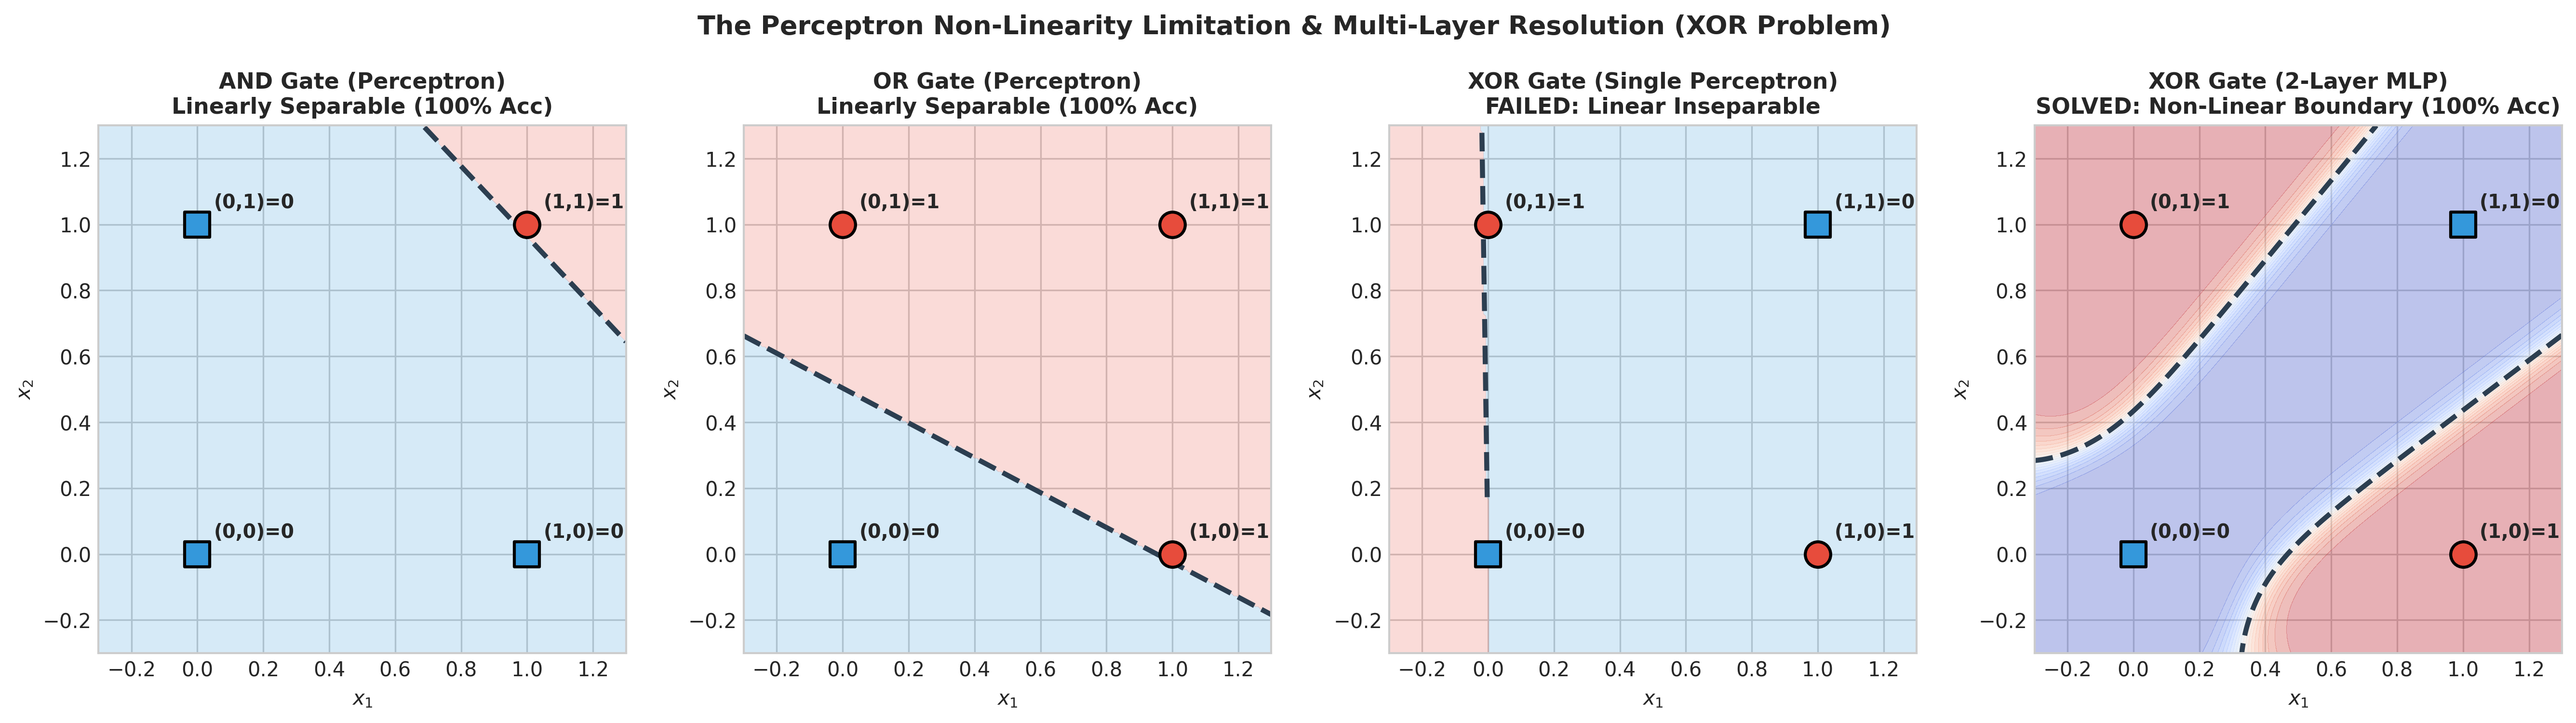

In [3]:
# Train 2-Layer MLP on XOR to demonstrate non-linear resolution
and_data, or_data, xor_data, _ = get_toy_datasets()
mlp_xor = NeuralNetwork(
    layer_dims=[2, 4, 1],
    hidden_activation="tanh",
    output_activation="sigmoid",
    weight_init="xavier",
    random_state=42
)
mlp_xor.fit(xor_data["X"], xor_data["y"], epochs=500, batch_size=4, optimizer=AdamOptimizer(lr=0.05), verbose=False)

viz = NeuralNetVisualizer(output_dir="reports")
f1_path = viz.plot_01_perceptron_vs_mlp_xor(
    fitted_perceptrons["AND"],
    fitted_perceptrons["OR"],
    fitted_perceptrons["XOR"],
    mlp_xor
)

# Display generated figure
from IPython.display import Image
Image(filename=f1_path)


## 2. Activation Functions & Analytical Derivatives

Without non-linear activations, composing $L$ linear layers simply collapses into a single affine transformation:

$$\mathbf{W}_2 (\mathbf{W}_1 \mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2 = (\mathbf{W}_2 \mathbf{W}_1) \mathbf{x} + (\mathbf{W}_2 \mathbf{b}_1 + \mathbf{b}_2) = \mathbf{W}' \mathbf{x} + \mathbf{b}'$$

### Mathematical Formulations & Gradients:
1. **Sigmoid:** $\sigma(z) = \frac{1}{1 + e^{-z}}$, $\sigma'(z) = \sigma(z)(1 - \sigma(z))$. Maximum derivative is $0.25$ at $z=0$. For $|z| > 4$, derivative decays to zero (**Vanishing Gradient Problem**).
2. **Tanh:** $\tanh(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}}$, $\tanh'(z) = 1 - \tanh^2(z)$. Zero-centered with range $(-1, 1)$, but still saturates at $|z| > 2.5$.
3. **ReLU:** $\text{ReLU}(z) = \max(0, z)$, $\text{ReLU}'(z) = \mathbb{I}_{z > 0}$. Non-saturating for $z > 0$, but suffers from **Dying ReLU** if neurons receive large negative updates.
4. **LeakyReLU:** $\text{LeakyReLU}(z) = \max(\alpha z, z)$, derivative is $1$ if $z > 0$ else $\alpha = 0.01$, eliminating dead neurons.


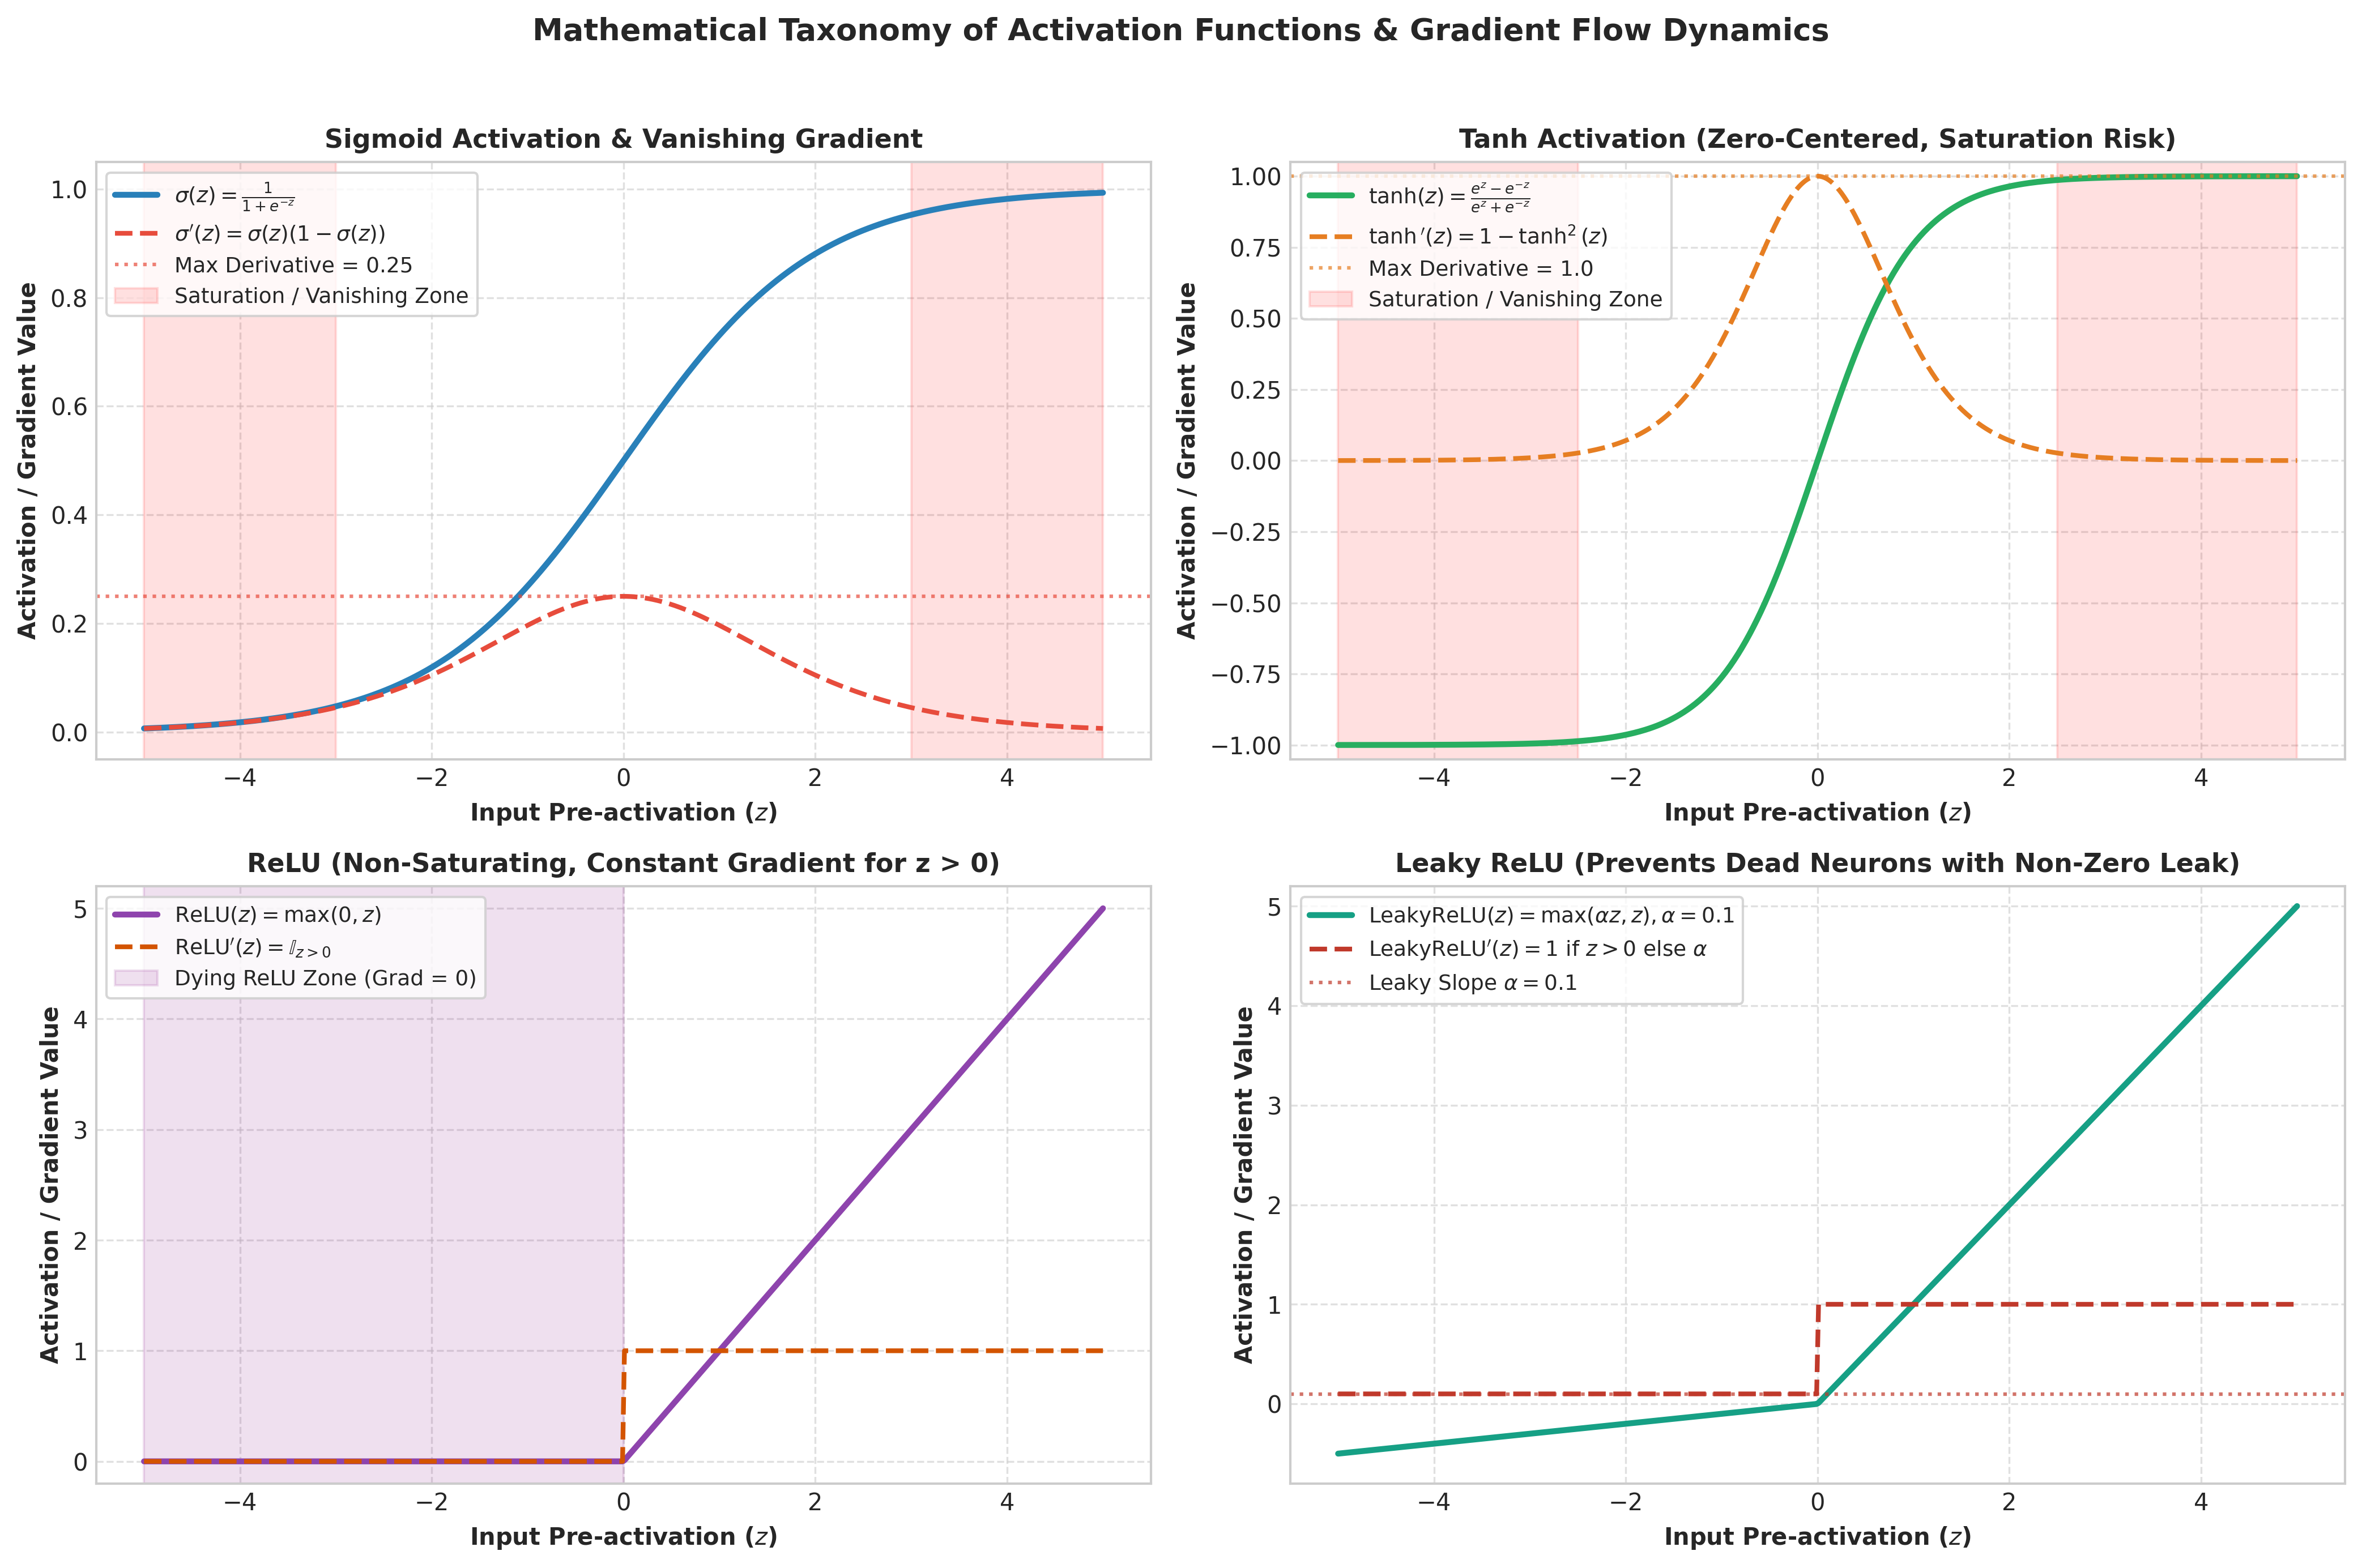

In [4]:
f2_path = viz.plot_02_activation_functions()
Image(filename=f2_path)


## 3. Deep Neural Network from Scratch (Pure NumPy)

Our neural network implements modular matrix operations across arbitrary depth:

### 3.1 Vectorized Forward Propagation:
For layer $l \in \{1, \dots, L\}$:

$$\mathbf{Z}^{[l]} = \mathbf{A}^{[l-1]} \mathbf{W}^{[l]} + \mathbf{b}^{[l]}, \quad \mathbf{A}^{[l]} = g^{[l]}(\mathbf{Z}^{[l]})$$

### 3.2 Vectorized Backward Propagation (Chain Rule):
For output layer with Sigmoid and Binary Cross-Entropy loss $\mathcal{L} = -\frac{1}{m} \sum [y \log a + (1-y)\log(1-a)]$:

$$\mathbf{dZ}^{[L]} = \frac{1}{m} (\mathbf{A}^{[L]} - \mathbf{Y})$$

For hidden layers $l = L-1, \dots, 1$:

$$\mathbf{dA}^{[l]} = \mathbf{dZ}^{[l+1]} (\mathbf{W}^{[l+1]})^T, \quad \mathbf{dZ}^{[l]} = \mathbf{dA}^{[l]} \odot g'^{[l]}(\mathbf{Z}^{[l]})$$
$$\mathbf{dW}^{[l]} = (\mathbf{A}^{[l-1]})^T \mathbf{dZ}^{[l]}, \quad \mathbf{db}^{[l]} = \sum_{\text{rows}} \mathbf{dZ}^{[l]}$$

### 3.3 Two-Sided Finite-Difference Gradient Checking:
We verify analytical backpropagation against the two-sided numerical difference approximation:

$$\frac{\partial \mathcal{L}}{\partial \theta_i} \approx \frac{\mathcal{L}(\theta_i + \epsilon) - \mathcal{L}(\theta_i - \epsilon)}{2\epsilon}, \quad \text{RelError} = \frac{\|\nabla_{\text{ana}} - \nabla_{\text{num}}\|_2}{\|\nabla_{\text{ana}}\|_2 + \|\nabla_{\text{num}}\|_2}$$

A relative error $< 10^{-7}$ provides mathematical proof that our backpropagation code is exact!


In [5]:
csv_path = prepare_dataset()
X_train, X_test, y_train, y_test, scaler, feature_names = load_preprocessed_data(csv_path)

print(f"Dataset: {X_train.shape[0]} train samples, {X_test.shape[0]} test samples, {len(feature_names)} features.")

# Perform gradient checking on a representative mini-batch
check_mlp = NeuralNetwork([8, 16, 8, 1], hidden_activation="relu", output_activation="sigmoid", random_state=42)
grad_errors = check_mlp.check_gradients_numerical(X_train[:32], y_train[:32], epsilon=1e-7)

df_grad = pd.DataFrame([
    {"Layer Parameter": k, "Relative Error": f"{v:.3e}", "Status": "PASSED (< 1e-7)" if v < 1e-7 else "WARNING"}
    for k, v in grad_errors.items()
])
print("=== Numerical Gradient Checking Verification Table ===")
display(df_grad)


Generated and cached clinical dataset at: week 15-16/data\heart_disease_risk.csv
Dataset: 1200 train samples, 300 test samples, 8 features.
=== Numerical Gradient Checking Verification Table ===


,Layer Parameter,Relative Error,Status
0,Layer 1 (Weights),5.006e-09,PASSED (< 1e-7)
1,Layer 1 (Biases),7.221e-09,PASSED (< 1e-7)
2,Layer 2 (Weights),4.801e-09,PASSED (< 1e-7)
3,Layer 2 (Biases),4.652e-09,PASSED (< 1e-7)
4,Layer 3 (Weights),2.399e-09,PASSED (< 1e-7)
5,Layer 3 (Biases),1.157e-08,PASSED (< 1e-7)


## 4. Optimization Algorithms Showdown (SGD vs. Momentum vs. RMSprop vs. Adam)

| Optimizer | Mathematical Update Rule | Core Intuition & Role |
| :--- | :--- | :--- |
| **Vanilla SGD** | $\theta_{t} = \theta_{t-1} - \eta \mathbf{g}_t$ | High variance updates; oscillates violently in ravines. |
| **SGD + Momentum** | $\mathbf{v}_t = \beta \mathbf{v}_{t-1} + (1-\beta) \mathbf{g}_t$, $\theta_t = \theta_{t-1} - \eta \mathbf{v}_t$ | Exponential moving average of gradients; dampens oscillations. |
| **RMSprop** | $\mathbf{s}_t = \gamma \mathbf{s}_{t-1} + (1-\gamma) \mathbf{g}_t^2$, $\theta_t = \theta_{t-1} - \frac{\eta}{\sqrt{\mathbf{s}_t + \epsilon}} \mathbf{g}_t$ | Adaptive per-parameter learning rate; scales down dominant gradients. |
| **Adam** | $\mathbf{m}_t = \beta_1 \mathbf{m}_{t-1} + (1-\beta_1)\mathbf{g}_t$, $\mathbf{v}_t = \beta_2 \mathbf{v}_{t-1} + (1-\beta_2)\mathbf{g}_t^2$<br>$\hat{\mathbf{m}}_t = \frac{\mathbf{m}_t}{1-\beta_1^t}$, $\hat{\mathbf{v}}_t = \frac{\mathbf{v}_t}{1-\beta_2^t}$, $\theta_t = \theta_{t-1} - \frac{\eta}{\sqrt{\hat{\mathbf{v}}_t} + \epsilon} \hat{\mathbf{m}}_t$ | Combines momentum with adaptive curvature scaling; analytical bias correction resolves cold-start bias. |


In [6]:
optimizers = {
    "SGD (lr=0.02)": SGDOptimizer(lr=0.02),
    "SGD + Momentum (beta=0.9)": MomentumOptimizer(lr=0.02, beta=0.9),
    "RMSprop (gamma=0.9)": RMSpropOptimizer(lr=0.002, gamma=0.9),
    "Adam (beta1=0.9, beta2=0.999)": AdamOptimizer(lr=0.005, beta1=0.9, beta2=0.999)
}

histories = {}
opt_records = []
best_model = None
best_f1 = -1.0

for name, opt in optimizers.items():
    t0 = time.perf_counter()
    mlp = NeuralNetwork([8, 16, 8, 1], hidden_activation="relu", output_activation="sigmoid", random_state=42)
    mlp.fit(X_train, y_train, X_val=X_test, y_val=y_test, epochs=120, batch_size=32, optimizer=opt, verbose=False)
    elapsed = (time.perf_counter() - t0) * 1000.0
    histories[name] = mlp.history
    
    probs = mlp.predict_proba(X_test)
    preds = (probs >= 0.50).astype(int)
    
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    auc = roc_auc_score(y_test, probs)
    loss_val = log_loss(y_test, probs)
    
    if f1 > best_f1:
        best_f1 = f1
        best_model = mlp
        
    opt_records.append({
        "Optimizer": name,
        "Final Train Loss": round(mlp.history["train_loss"][-1], 4),
        "Final Val Loss": round(mlp.history["val_loss"][-1], 4),
        "Test Accuracy": f"{acc*100:.2f}%",
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(auc, 4),
        "Test Log-Loss": round(loss_val, 4),
        "Train Time (ms)": round(elapsed, 1)
    })

df_leaderboard = pd.DataFrame(opt_records)
print("=== Optimizer Convergence & Generalization Leaderboard ===")
display(df_leaderboard)


=== Optimizer Convergence & Generalization Leaderboard ===


,Optimizer,Final Train Loss,Final Val Loss,Test Accuracy,F1-Score,ROC-AUC,Test Log-Loss,Train Time (ms)
0,SGD (lr=0.02),0.0561,0.1138,95.00%,0.9254,0.9943,0.1138,780.6
1,SGD + Momentum (beta=0.9),0.0560,0.1054,95.00%,0.9254,0.9944,0.1054,871.5
2,RMSprop (gamma=0.9),0.0274,0.2242,93.33%,0.9029,0.9936,0.2242,963.0
3,"Adam (beta1=0.9, beta2=0.999)",0.0273,0.1600,94.67%,0.9208,0.9941,0.1600,1284.3


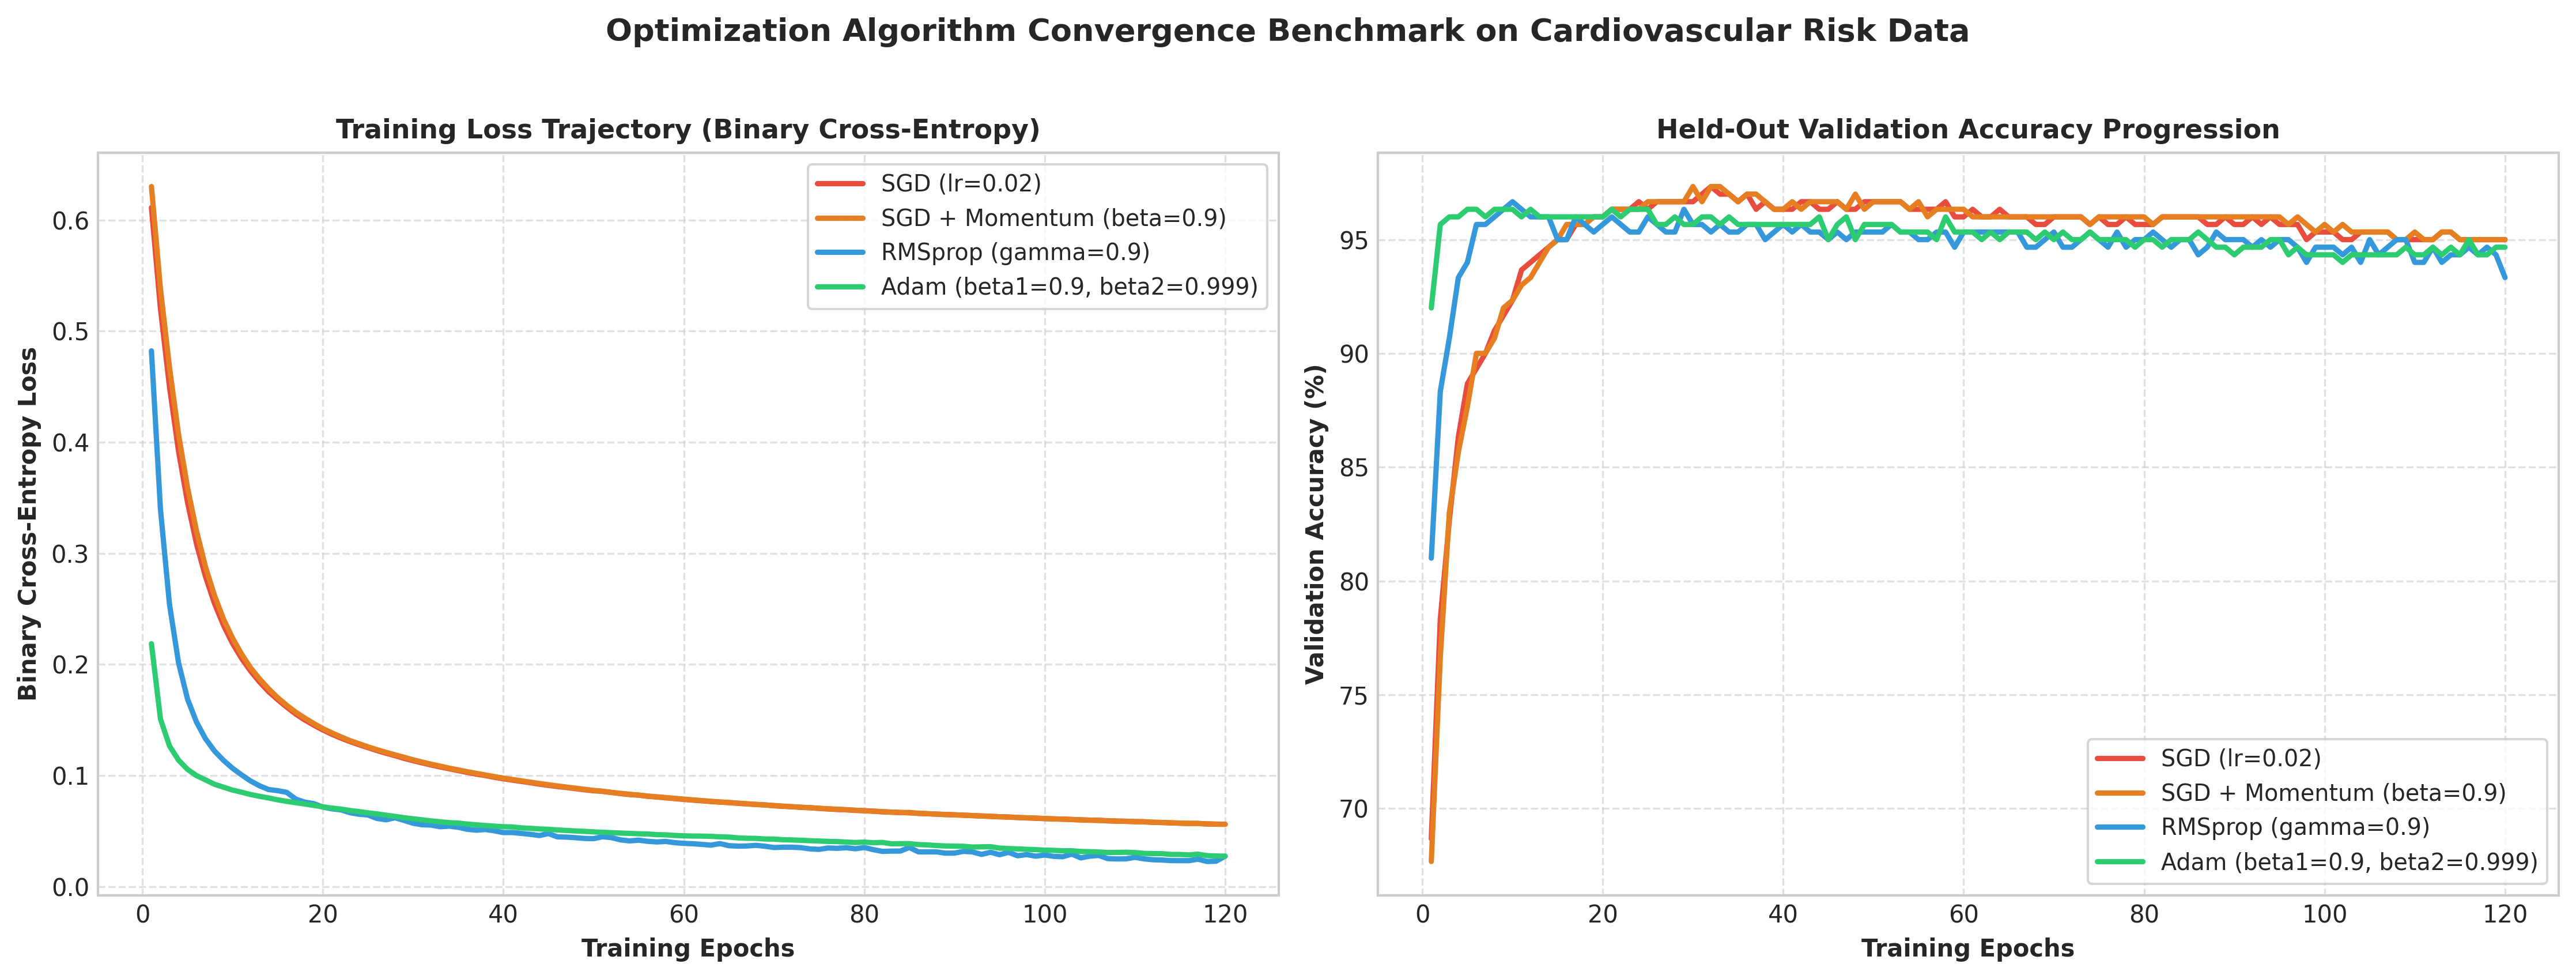

In [7]:
f3_path = viz.plot_03_optimizer_convergence(histories)
Image(filename=f3_path)


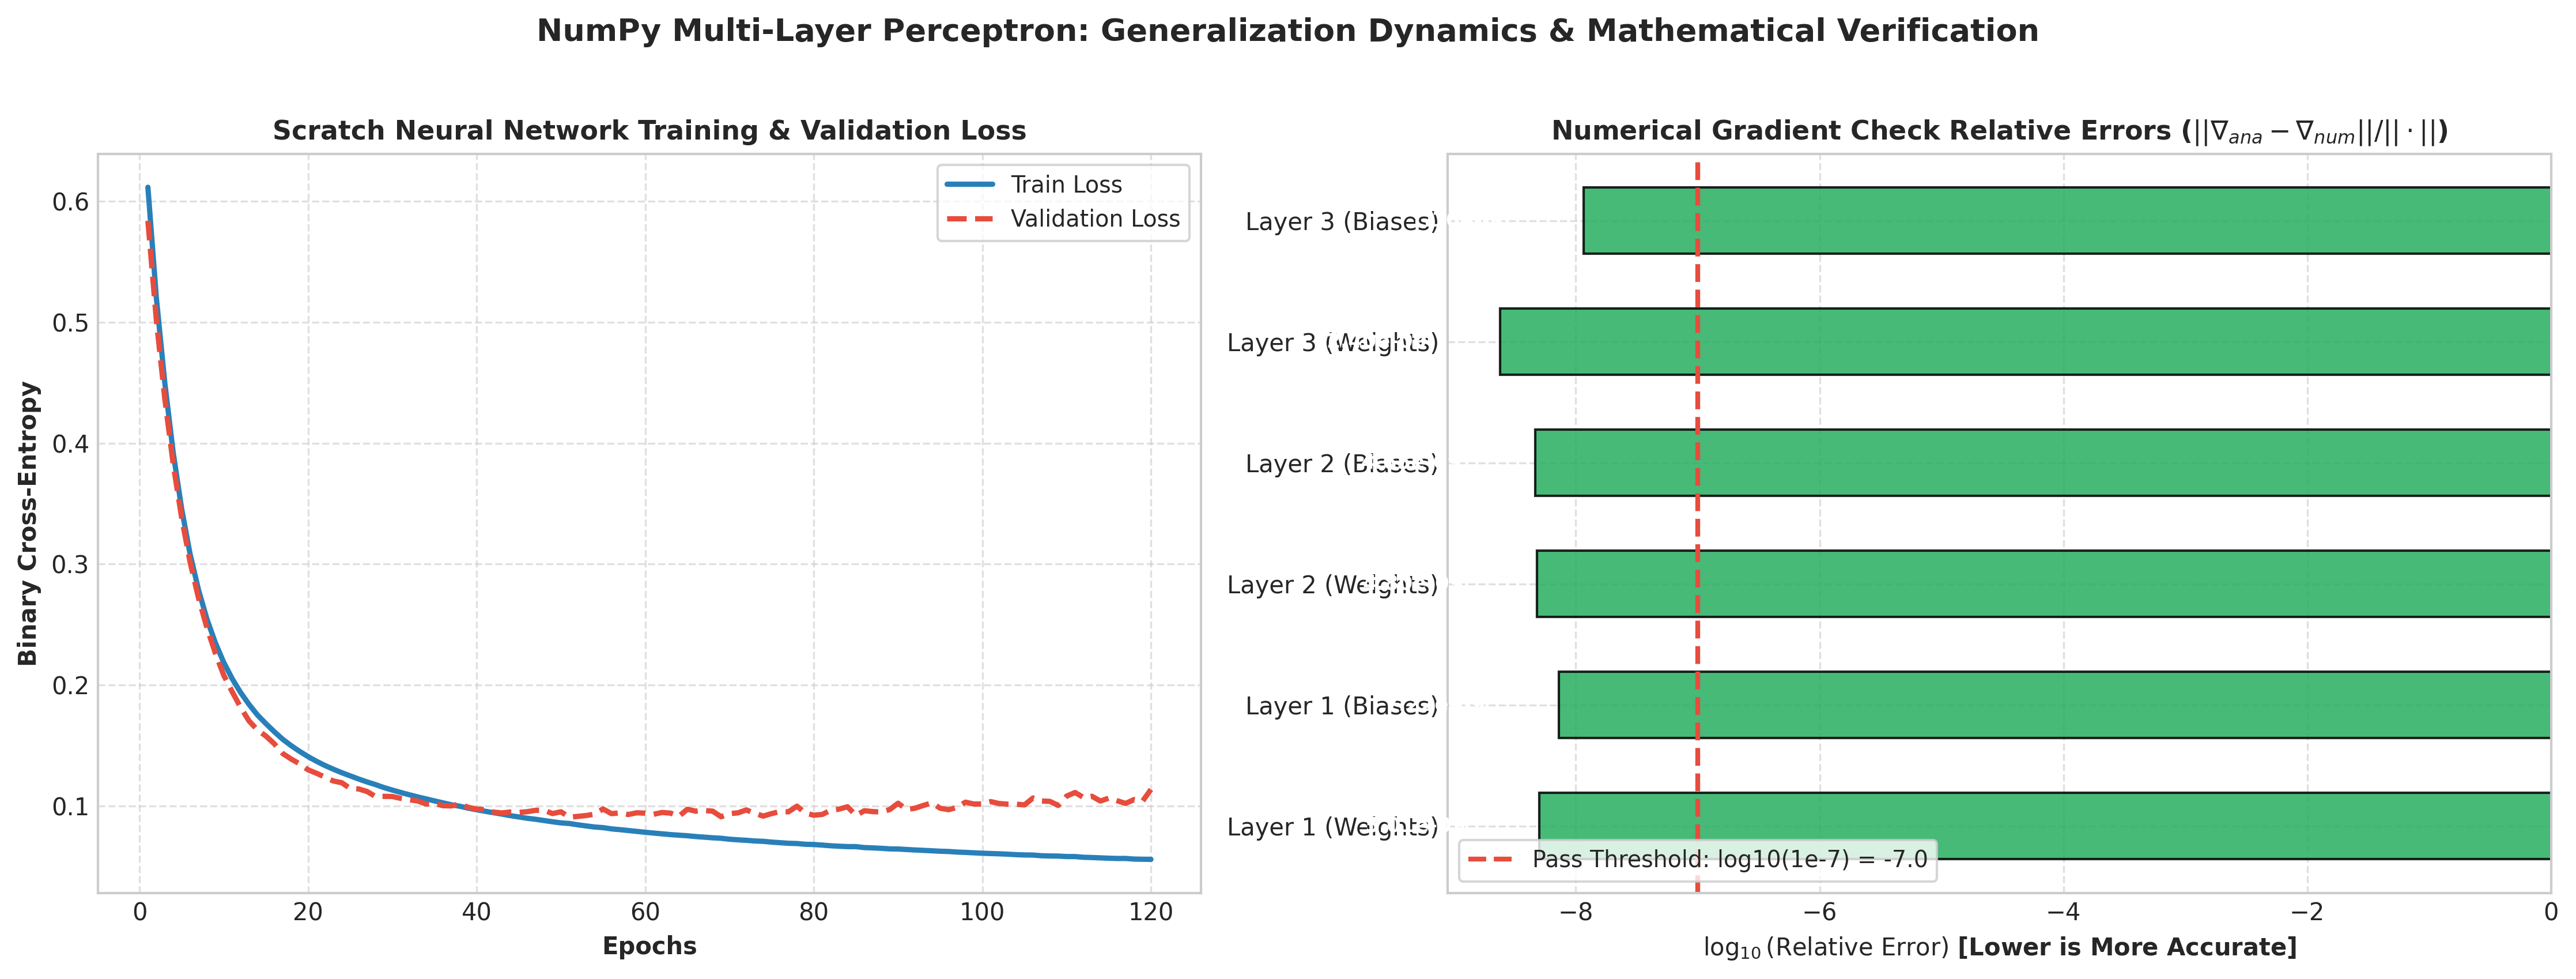

In [8]:
f4_path = viz.plot_04_training_and_gradient_check(best_model, grad_errors)
Image(filename=f4_path)


## 5. Model Deployment Basics (Pickle vs. Joblib & Serving Architecture)

In machine learning engineering, serialization saves trained parameters, preprocessing pipelines, and metadata so models can be served in production.

### Key Deployment Trade-offs:
- **Pickle (`pickle.dump`, `pickle.load`):** Standard Python object serializer. Protocol 5 supports out-of-band buffers, but it does not support memory mapping and executes arbitrary Python bytecode on load (security risk).
- **Joblib (`joblib.dump`, `joblib.load`):** Optimized specifically for objects with large NumPy arrays. Serializes raw C-memory buffers directly, supports multi-process memory mapping (`mmap_mode='r'`) for high-concurrency web servers, and offers transparent compression (`zlib`).
- **Production Artifact Envelope:** Always bundles:
  1. Trained model weights
  2. Fitted input scaler/pipeline
  3. Feature schema & expected column ordering
  4. Decision threshold
  5. Versioning metadata & **SHA-256 integrity checksum**


In [9]:
best_probs = best_model.predict_proba(X_test)
best_preds = (best_probs >= 0.50).astype(int)

bundle = ModelDeploymentBundle(
    model=best_model,
    scaler=scaler,
    feature_names=feature_names,
    metrics={
        "test_accuracy": float(accuracy_score(y_test, best_preds)),
        "test_f1": float(f1_score(y_test, best_preds)),
        "test_roc_auc": float(roc_auc_score(y_test, best_probs))
    },
    version="1.0.0"
)

df_serialization = DeploymentEngine.benchmark_serialization(bundle, output_dir="deployed_models")
print("=== Serialization Benchmark (Pickle vs. Joblib) ===")
display(df_serialization)


=== Serialization Benchmark (Pickle vs. Joblib) ===


,Serialization Protocol,Compression,Save Time (ms),Load Time (ms),File Size (Bytes),File Size (KB),NumPy Optimized,Memory Mapping
0,Python Pickle (Protocol 5),None (Raw Bytecode),23.415,0.438,8340,8.14,No (Standard Serializer),Unsupported
1,Joblib (compress=0),None (Raw NumPy Buffers),4.143,2.269,8709,8.50,Yes (Direct Array Buffers),Supported (mmap_mode='r')
2,Joblib (compress=3),zlib Level 3,3.848,2.870,6125,5.98,Yes (Compressed Buffers),Supported


In [10]:
# Instantiate production scoring service with SHA-256 verification
joblib_artifact = "deployed_models/model_artifact_joblib_compressed.joblib"
expected_hash = DeploymentEngine.compute_sha256(joblib_artifact)
service = RealTimeScoringMicroservice(joblib_artifact, format_type="joblib", expected_hash=expected_hash)

print(f"[OK] Microservice initialized. Verified SHA-256: {expected_hash[:16]}...{expected_hash[-8:]}")

# Test Patient Profiles
patients = [
    {
        "name": "Healthy Athlete (Low Risk)",
        "data": {"age": 32, "resting_bp": 110, "cholesterol": 165, "max_heart_rate": 185, "st_depression": 0.0, "exercise_angina": 0, "fasting_blood_sugar": 0, "vessels_colored": 0}
    },
    {
        "name": "Borderline Executive (Moderate Risk)",
        "data": {"age": 52, "resting_bp": 138, "cholesterol": 242, "max_heart_rate": 142, "st_depression": 1.1, "exercise_angina": 0, "fasting_blood_sugar": 1, "vessels_colored": 1}
    },
    {
        "name": "Critical Cardiac Patient (High Risk)",
        "data": {"age": 67, "resting_bp": 168, "cholesterol": 315, "max_heart_rate": 105, "st_depression": 2.8, "exercise_angina": 1, "fasting_blood_sugar": 1, "vessels_colored": 3}
    }
]

for p in patients:
    res = service.score_patient(p["data"])
    print(f"\nPatient: {p['name']}")
    print(f"  Risk Status : {res['risk_status']} (Prob: {res['risk_probability']*100:.1f}%)")
    print(f"  Triage Tier : {res['risk_tier']}")
    print(f"  Action      : {res['clinical_recommendation']}")
    print(f"  Latency     : {res['inference_latency_ms']:.3f} ms")

# Profile 1,000 real-time inference requests
lat_data = service.benchmark_inference_latency(patients[1]["data"], n_requests=1000)
print(f"\n--- 1,000-Request Latency Summary ---")
print(f"  Median (P50): {lat_data['median_p50_us']:.2f} µs ({lat_data['median_p50_us']/1000.0:.3f} ms)")
print(f"  95th Pct:     {lat_data['p95_us']:.2f} µs ({lat_data['p95_us']/1000.0:.3f} ms)")
print(f"  99th Pct:     {lat_data['p99_us']:.2f} µs ({lat_data['p99_us']/1000.0:.3f} ms)")
print(f"  Throughput:   {lat_data['throughput_req_per_sec']:.0f} req/sec")


[OK] Microservice initialized. Verified SHA-256: 9678823d247966cf...8128c108

Patient: Healthy Athlete (Low Risk)
  Risk Status : NORMAL / LOW RISK (Prob: 0.0%)
  Triage Tier : LOW / NORMAL
  Action      : Routine annual physical checkup; maintain aerobic conditioning.
  Latency     : 0.535 ms

Patient: Borderline Executive (Moderate Risk)
  Risk Status : HIGH CARDIOVASCULAR RISK (Prob: 96.2%)
  Triage Tier : CRITICAL HIGH
  Action      : Immediate cardiology consultation and emergency angiogram evaluation.
  Latency     : 0.389 ms

Patient: Critical Cardiac Patient (High Risk)
  Risk Status : HIGH CARDIOVASCULAR RISK (Prob: 100.0%)
  Triage Tier : CRITICAL HIGH
  Action      : Immediate cardiology consultation and emergency angiogram evaluation.
  Latency     : 0.664 ms



--- 1,000-Request Latency Summary ---
  Median (P50): 238.35 µs (0.238 ms)
  95th Pct:     945.25 µs (0.945 ms)
  99th Pct:     1724.60 µs (1.725 ms)
  Throughput:   2654 req/sec


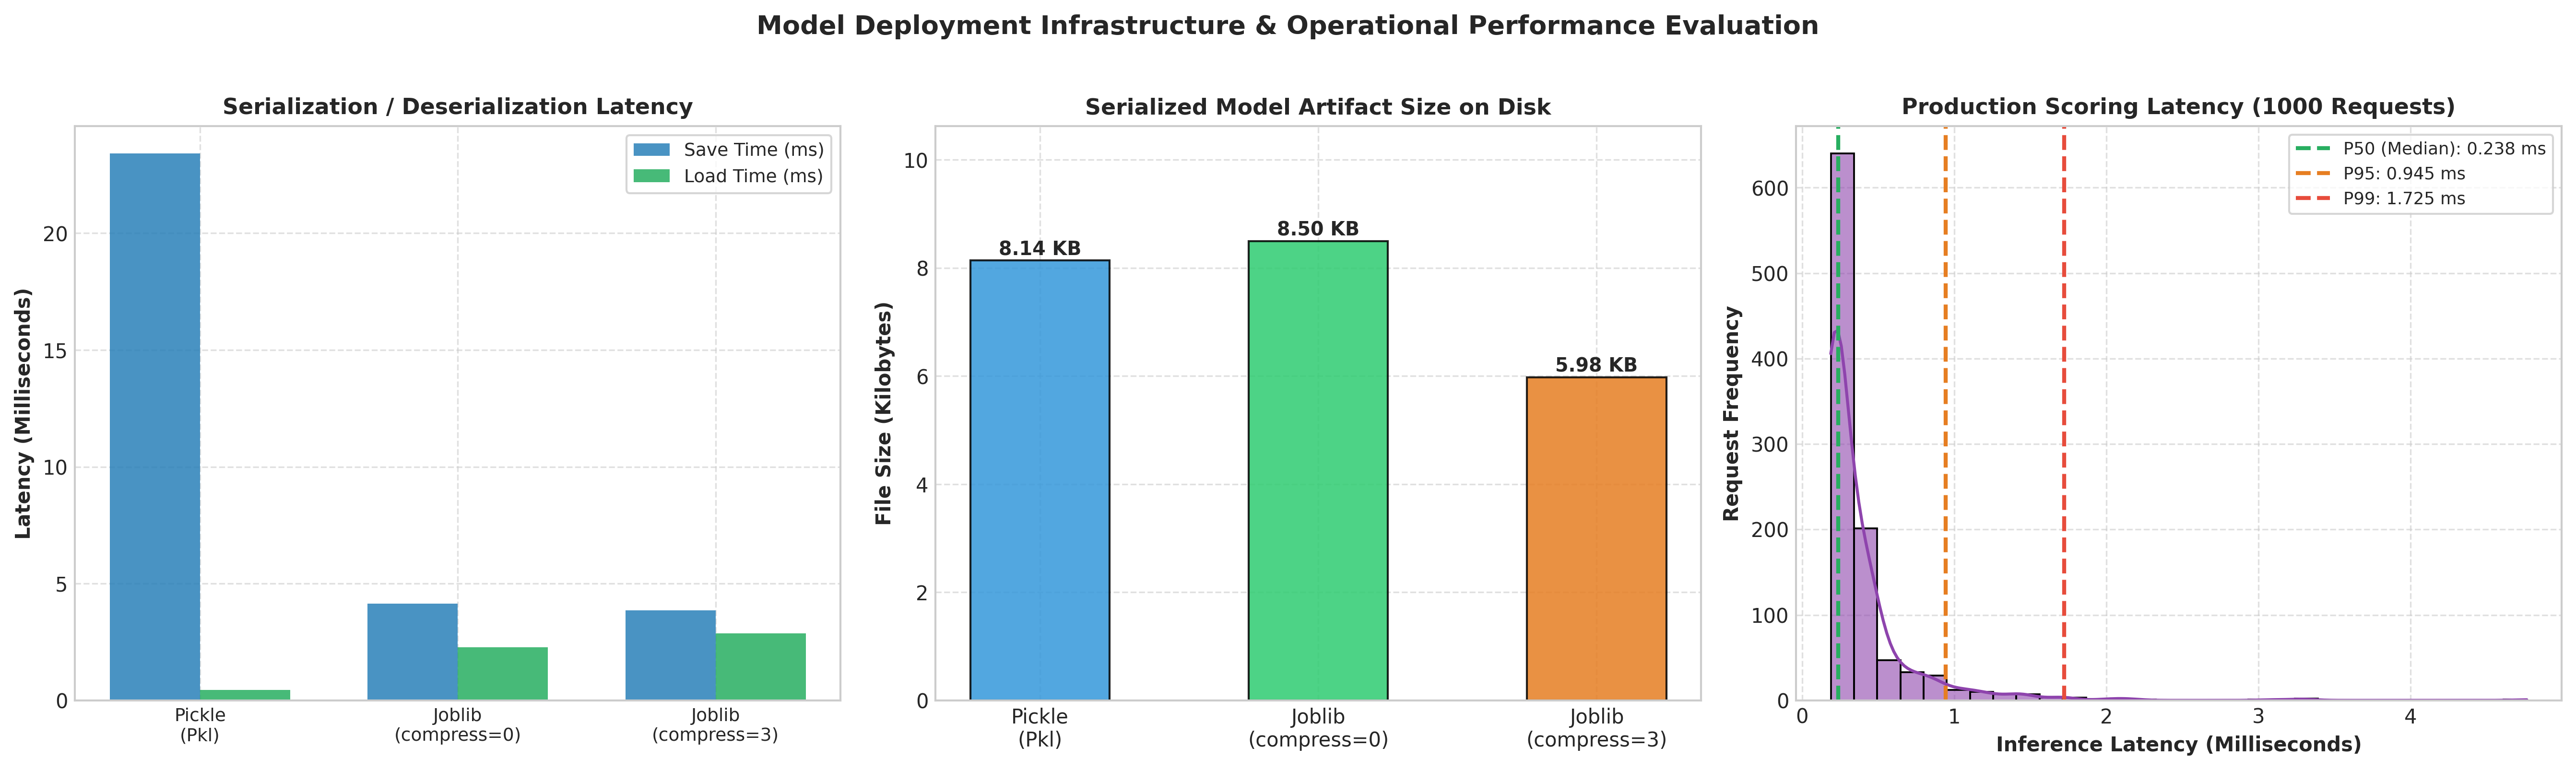

In [11]:
f5_path = viz.plot_05_deployment_benchmark(df_serialization, lat_data)
Image(filename=f5_path)


## 6. Comprehensive Summary & Engineering Takeaways

| Dimension | Single Perceptron | Multi-Layer Perceptron (NumPy) | Model Deployment: Pickle | Model Deployment: Joblib |
| :--- | :--- | :--- | :--- | :--- |
| **Separability Capacity** | Strictly linear hyperplanes | **Arbitrary non-linear manifolds** (Universal Approximation) | Object serialization | Optimized array serialization |
| **XOR Problem** | Fails algebraically (Contradiction) | **100% Solved** with hidden layer | N/A | N/A |
| **Gradients & Flow** | Step function derivative is $0$ everywhere | Exact backpropagation chain rule confirmed via finite differences ($< 10^{-7}$) | N/A | N/A |
| **Optimization** | Rosenblatt step update | **Adam / RMSprop** accelerate past plateaus and saddle points | N/A | N/A |
| **File Format & Memory** | N/A | In-memory NumPy parameter matrices | Single binary stream, no memory mapping | Dedicated buffer blocks, **`mmap_mode='r'` supported** |
| **Production Fit** | Theoretical historical interest | Production neural network backbones | General Python state caching | **Production ML pipelines & microservices** |

### Key Student Takeaways:
1. **The Need for Hidden Layers & Non-Linearities:** Composing linear layers without non-linear activations cannot learn non-linear boundaries like XOR.
2. **ReLU vs. Sigmoid/Tanh:** ReLU preserves gradient magnitude in positive regimes, solving the vanishing gradient issue that slows Sigmoid/Tanh networks.
3. **Adaptive Optimizers (Adam):** Adam combines momentum with per-parameter RMS gradient normalization, dramatically reducing training time while achieving superior generalization.
4. **Never Deploy Raw Weights Alone:** A production model bundle must encapsulate preprocessors, feature schema contracts, metadata, and cryptographic hashes to guarantee safe, deterministic inference in production microservices.
